In [ ]:
#@title Configure { display-mode: "form" }

#@markdown Folder **in Drive** holding the two archives:
ARCHIVE_DIR = "/content/drive/MyDrive/STAT 683"  #@param {type:"string"}

#@markdown Where to extract (Colab local disk — fast, wiped on disconnect):
DATAROOT = "/content/nuscenes"  #@param {type:"string"}

VERSION = "v1.0-mini"  #@param ["v1.0-mini", "v1.0-trainval"]

#@markdown Untick if you already extracted in this session:
DO_EXTRACT = True  #@param {type:"boolean"}

import os, time
from google.colab import drive
drive.mount('/content/drive')

print(f"\narchives : {ARCHIVE_DIR}")
if os.path.isdir(ARCHIVE_DIR):
    for f in sorted(os.listdir(ARCHIVE_DIR)):
        sz = os.path.getsize(os.path.join(ARCHIVE_DIR, f)) / 1e9
        print(f"           {f}  ({sz:.2f} GB)")
else:
    print("           NOT FOUND — fix ARCHIVE_DIR above")

Mounted at /content/drive

archives : /content/drive/MyDrive/STAT 683
           can_bus.zip  (0.78 GB)
           v1.0-mini.tgz  (4.17 GB)


In [ ]:
#@title Extract to local disk  (~1–2 min)

if DO_EXTRACT:
    os.makedirs(DATAROOT, exist_ok=True)
    t0 = time.time()

    # Copy off Drive first — extracting straight from a Drive path is far slower.
    print("copying archives to local disk...")
    !cp "{ARCHIVE_DIR}/v1.0-mini.tgz" /content/ 2>/dev/null
    !cp "{ARCHIVE_DIR}/can_bus.zip"   /content/ 2>/dev/null

    print("extracting v1.0-mini.tgz...")
    !tar -xzf /content/v1.0-mini.tgz -C "{DATAROOT}"

    print("extracting can_bus.zip...")
    !unzip -q -o /content/can_bus.zip -d "{DATAROOT}"

    # Free ~5 GB — the archives are still in Drive.
    !rm -f /content/v1.0-mini.tgz /content/can_bus.zip
    print(f"\ndone in {time.time() - t0:.0f}s")

print("\ncontents of DATAROOT:")
for d in sorted(os.listdir(DATAROOT)):
    print(f"  {d}")

n_tables = len([f for f in os.listdir(f"{DATAROOT}/{VERSION}") if f.endswith('.json')])
print(f"\nmetadata tables: {n_tables}   (13 = correct base set; 2–3 = you grabbed an expansion)")

copying archives to local disk...
extracting v1.0-mini.tgz...
extracting can_bus.zip...

done in 263s

contents of DATAROOT:
  .v1.0-mini.txt
  LICENSE
  can_bus
  maps
  samples
  sweeps
  v1.0-mini

metadata tables: 13   (13 = correct base set; 2–3 = you grabbed an expansion)


In [ ]:
#@title Extract to local disk  (~1–2 min)

if DO_EXTRACT:
    os.makedirs(DATAROOT, exist_ok=True)
    t0 = time.time()

    # Copy off Drive first — extracting straight from a Drive path is far slower.
    print("copying archives to local disk...")
    !cp "{ARCHIVE_DIR}/v1.0-mini.tgz" /content/ 2>/dev/null
    !cp "{ARCHIVE_DIR}/can_bus.zip"   /content/ 2>/dev/null

    print("extracting v1.0-mini.tgz...")
    !tar -xzf /content/v1.0-mini.tgz -C "{DATAROOT}"

    print("extracting can_bus.zip...")
    !unzip -q -o /content/can_bus.zip -d "{DATAROOT}"

    # Free ~5 GB — the archives are still in Drive.
    !rm -f /content/v1.0-mini.tgz /content/can_bus.zip
    print(f"\ndone in {time.time() - t0:.0f}s")

print("\ncontents of DATAROOT:")
for d in sorted(os.listdir(DATAROOT)):
    print(f"  {d}")

n_tables = len([f for f in os.listdir(f"{DATAROOT}/{VERSION}") if f.endswith('.json')])
print(f"\nmetadata tables: {n_tables}   (13 = correct base set; 2–3 = you grabbed an expansion)")

copying archives to local disk...
extracting v1.0-mini.tgz...
extracting can_bus.zip...

done in 238s

contents of DATAROOT:
  .v1.0-mini.txt
  LICENSE
  can_bus
  maps
  samples
  sweeps
  v1.0-mini

metadata tables: 13   (13 = correct base set; 2–3 = you grabbed an expansion)


In [ ]:
#@title Install the devkit
!pip install -q nuscenes-devkit
print("ok")

In [ ]:
!pip install -q --no-deps nuscenes-devkit
!pip install -q pyquaternion cachetools descartes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 6.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
nuscenes-devkit 1.2.0 requires fire, which is not installed.
nuscenes-devkit 1.2.0 requires parameterized, which is not installed.
nuscenes-devkit 1.2.0 requires numpy<2.0.0,>=1.22.0, but you have numpy 2.1.3 which is incompatible.
nuscenes-devkit 1.2.0 requires Shapely~=2.0.3, but you have shapely 2.1.2 which is incompatible.


In [ ]:
import numpy as np, shapely
from nuscenes.nuscenes import NuScenes
from nuscenes.can_bus.can_bus_api import NuScenesCanBus
print("numpy", np.__version__, "| shapely", shapely.__version__)

nusc = NuScenes(version=VERSION, dataroot=DATAROOT, verbose=False)
can  = NuScenesCanBus(dataroot=DATAROOT)
s = nusc.scene[0]
print("scenes", len(nusc.scene), "| samples", len(nusc.sample))
print("CAN msgs", len(can.get_messages(s["name"], "vehicle_monitor")))
print("PASS")

numpy 2.1.3 | shapely 2.1.2
scenes 10 | samples 404
CAN msgs 38
PASS


In [ ]:
#@title 1 · Footprint — files, not gigabytes

from collections import Counter

n_files, n_bytes, per_dir = 0, 0, Counter()
for dirpath, _, filenames in os.walk(DATAROOT):
    n_files += len(filenames)
    top = os.path.relpath(dirpath, DATAROOT).split(os.sep)[0]
    per_dir[top] += len(filenames)
    for f in filenames:
        try:
            n_bytes += os.path.getsize(os.path.join(dirpath, f))
        except OSError:
            pass

print(f"total files : {n_files:,}")
print(f"total size  : {n_bytes / 1e9:.2f} GB\n")
for d, c in per_dir.most_common():
    print(f"  {d:<16} {c:>8,} files")

print(f"\nScaling note: mini is 10 of 1000 scenes. Full trainval is roughly")
print(f"{n_files * 85:,.0f} files by this ratio — against a 250,000 file quota on")
print("HPRC scratch. Shard into tar/webdataset before moving past mini.")

total files : 39,057
total size  : 10.01 GB

  sweeps             26,358 files
  can_bus             7,832 files
  samples             4,848 files
  v1.0-mini              13 files
  maps                    4 files
  .                       2 files

Scaling note: mini is 10 of 1000 scenes. Full trainval is roughly
3,319,845 files by this ratio — against a 250,000 file quota on
HPRC scratch. Shard into tar/webdataset before moving past mini.


In [ ]:
#@title 2 · Structure

from nuscenes.nuscenes import NuScenes
nusc = NuScenes(version=VERSION, dataroot=DATAROOT, verbose=False)

print(f"scenes      : {len(nusc.scene)}")
print(f"samples     : {len(nusc.sample)}        annotated keyframes @ 2 Hz")
print(f"sample_data : {len(nusc.sample_data):,}      every reading, sweeps included")
print(f"annotations : {len(nusc.sample_annotation):,}\n")

ch = Counter(
    nusc.get("sensor", nusc.get("calibrated_sensor",
             sd["calibrated_sensor_token"])["sensor_token"])["channel"]
    for sd in nusc.sample_data
)
for c, n in sorted(ch.items(), key=lambda kv: -kv[1]):
    print(f"  {c:<24} {n:>7,}")


scenes      : 10
samples     : 404        annotated keyframes @ 2 Hz
sample_data : 31,206      every reading, sweeps included
annotations : 18,538

  LIDAR_TOP                  3,935
  RADAR_FRONT_LEFT           2,686
  RADAR_FRONT_RIGHT          2,673
  RADAR_FRONT                2,635
  RADAR_BACK_RIGHT           2,635
  RADAR_BACK_LEFT            2,634
  CAM_FRONT_LEFT             2,344
  CAM_FRONT                  2,342
  CAM_BACK_RIGHT             2,342
  CAM_FRONT_RIGHT            2,338
  CAM_BACK_LEFT              2,327
  CAM_BACK                   2,315


In [ ]:
#@title 3 · One scene

scene = nusc.scene[0]
first = nusc.get("sample", scene["first_sample_token"])
last  = nusc.get("sample", scene["last_sample_token"])
dur   = (last["timestamp"] - first["timestamp"]) / 1e6

print(f"name        : {scene['name']}")
print(f"description : {scene['description']}")
print(f"keyframes   : {scene['nbr_samples']}")
print(f"duration    : {dur:.1f}s  ({scene['nbr_samples']/dur:.2f} Hz)\n")
for c in first["data"]:
    print(f"  {c}")

name        : scene-0061
description : Parked truck, construction, intersection, turn left, following a van
keyframes   : 39
duration    : 19.1s  (2.04 Hz)

  RADAR_FRONT
  RADAR_FRONT_LEFT
  RADAR_FRONT_RIGHT
  RADAR_BACK_LEFT
  RADAR_BACK_RIGHT
  LIDAR_TOP
  CAM_FRONT
  CAM_FRONT_RIGHT
  CAM_BACK_RIGHT
  CAM_BACK
  CAM_BACK_LEFT
  CAM_FRONT_LEFT


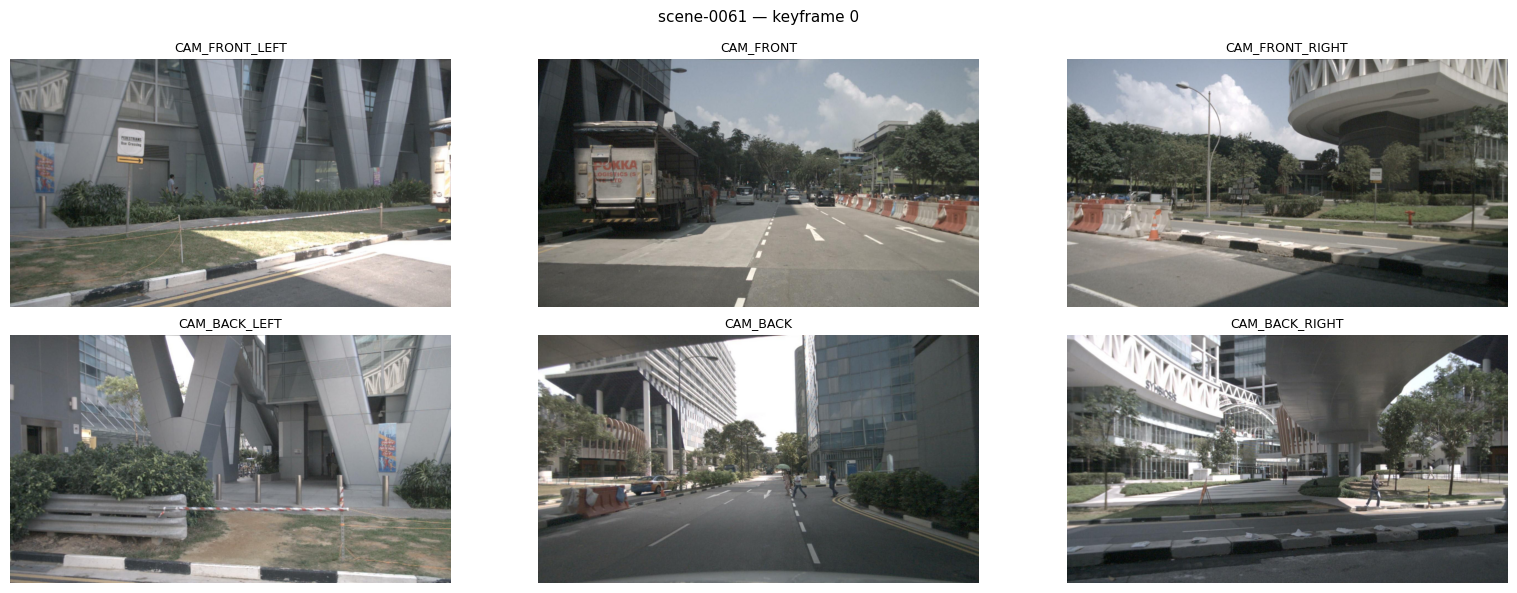

In [ ]:
#@title 4 · The six cameras

import matplotlib.pyplot as plt
from PIL import Image

order = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT",
         "CAM_BACK_LEFT",  "CAM_BACK",  "CAM_BACK_RIGHT"]
fig, axes = plt.subplots(2, 3, figsize=(16, 6))
for ax, cam in zip(axes.ravel(), order):
    sd = nusc.get("sample_data", first["data"][cam])
    ax.imshow(Image.open(os.path.join(DATAROOT, sd["filename"])))
    ax.set_title(cam, fontsize=9)
    ax.axis("off")
plt.suptitle(f"{scene['name']} — keyframe 0", fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
#@title 5 · CAN bus — action and state

import numpy as np
from nuscenes.can_bus.can_bus_api import NuScenesCanBus

can = NuScenesCanBus(dataroot=DATAROOT)
blacklist = set(f"scene-{n:04d}" for n in getattr(can, "can_blacklist", []))
print(f"scenes with unusable CAN data: {sorted(blacklist) or 'none'}\n")

assert scene["name"] not in blacklist, "pick a different scene"

for msg in ["vehicle_monitor", "steeranglefeedback", "pose", "ms_imu"]:
    try:
        rows = can.get_messages(scene["name"], msg)
    except Exception as e:
        print(f"{msg:<22} unavailable ({type(e).__name__})")
        continue
    ts = np.array([r["utime"] for r in rows], dtype=np.int64)
    hz = len(rows) / ((ts[-1] - ts[0]) / 1e6)
    print(f"{msg:<22} {len(rows):>6} msgs   {hz:>6.1f} Hz")
    print(f"    {', '.join(sorted(rows[0].keys()))}\n")

scenes with unusable CAN data: ['scene-0161', 'scene-0162', 'scene-0163', 'scene-0164', 'scene-0165', 'scene-0166', 'scene-0167', 'scene-0168', 'scene-0170', 'scene-0171', 'scene-0172', 'scene-0173', 'scene-0174', 'scene-0175', 'scene-0176', 'scene-0309', 'scene-0310', 'scene-0311', 'scene-0312', 'scene-0313', 'scene-0314']

vehicle_monitor            38 msgs      2.0 Hz
    available_distance, battery_level, brake, brake_switch, gear_position, left_signal, rear_left_rpm, rear_right_rpm, right_signal, steering, steering_speed, throttle, utime, vehicle_speed, yaw_rate

steeranglefeedback       1797 msgs     93.9 Hz
    utime, value

pose                      938 msgs     49.0 Hz
    accel, orientation, pos, rotation_rate, utime, vel

ms_imu                   1899 msgs     99.2 Hz
    linear_accel, q, rotation_rate, utime



vehicle_monitor        median  429.7 ms   p95  481.0 ms   max  929.8 ms
steeranglefeedback     median    7.4 ms   p95   25.7 ms   max   35.8 ms
pose                   median    7.8 ms   p95   20.2 ms   max   28.1 ms


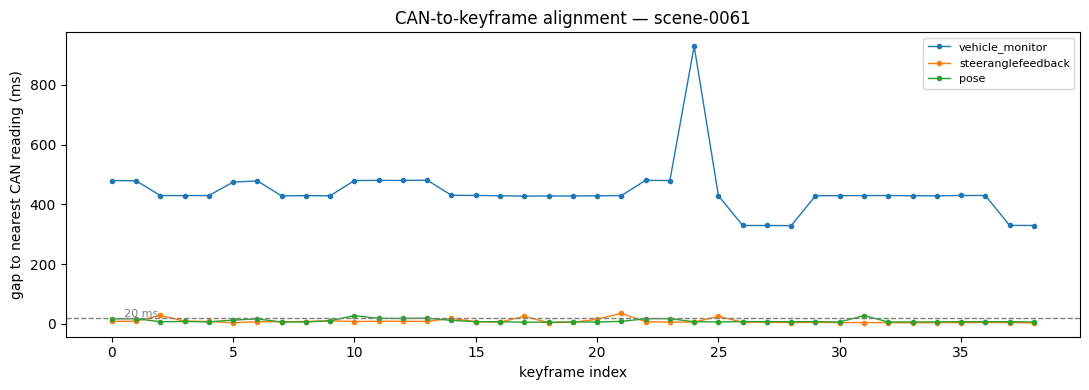


Under ~20 ms: nearest-neighbour is defensible.
Above it: interpolate, or resample onto a fixed grid.
Record whichever you pick — it changes what the model learns.


In [ ]:
#@title 6 · Alignment — the decision to settle now

key_ts, tok = [], scene["first_sample_token"]
while tok:
    s = nusc.get("sample", tok)
    key_ts.append(s["timestamp"])
    tok = s["next"]
key_ts = np.array(key_ts, dtype=np.int64)

fig, ax = plt.subplots(figsize=(11, 4))
for msg in ["vehicle_monitor", "steeranglefeedback", "pose"]:
    try:
        rows = can.get_messages(scene["name"], msg)
    except Exception:
        continue
    can_ts = np.array([r["utime"] for r in rows], dtype=np.int64)
    idx = np.searchsorted(can_ts, key_ts).clip(0, len(can_ts) - 1)
    gap = np.abs(can_ts[idx] - key_ts) / 1e3
    print(f"{msg:<22} median {np.median(gap):6.1f} ms   "
          f"p95 {np.percentile(gap, 95):6.1f} ms   max {gap.max():6.1f} ms")
    ax.plot(gap, marker="o", ms=3, lw=1, label=msg)

ax.axhline(20, ls="--", lw=1, color="grey")
ax.text(0.5, 22, "20 ms", fontsize=8, color="grey")
ax.set_xlabel("keyframe index")
ax.set_ylabel("gap to nearest CAN reading (ms)")
ax.set_title(f"CAN-to-keyframe alignment — {scene['name']}")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("\nUnder ~20 ms: nearest-neighbour is defensible.")
print("Above it: interpolate, or resample onto a fixed grid.")
print("Record whichever you pick — it changes what the model learns.")

In [ ]:
#@title 7 · Build the per-keyframe (action, state) table

import pandas as pd

vm = pd.DataFrame(can.get_messages(scene["name"], "vehicle_monitor")).sort_values("utime")
print("vehicle_monitor columns:\n ", list(vm.columns), "\n")

joined = pd.merge_asof(
    pd.DataFrame({"utime": key_ts}).sort_values("utime"),
    vm, on="utime", direction="nearest",
)
display(joined.head(12))
print(f"shape: {joined.shape}  — one row per keyframe, ready to condition on.")

# The columns that matter for an action-conditioned world model.
ACTION = [c for c in ["steering", "throttle", "brake"] if c in joined.columns]
STATE  = [c for c in ["vehicle_speed", "yaw_rate"]      if c in joined.columns]
print(f"\naction columns found: {ACTION}")
print(f"state  columns found: {STATE}")

vehicle_monitor columns:
  ['available_distance', 'battery_level', 'brake', 'brake_switch', 'gear_position', 'left_signal', 'rear_left_rpm', 'rear_right_rpm', 'right_signal', 'steering', 'steering_speed', 'throttle', 'utime', 'vehicle_speed', 'yaw_rate'] 



,utime,available_distance,battery_level,brake,brake_switch,gear_position,left_signal,rear_left_rpm,rear_right_rpm,right_signal,steering,steering_speed,throttle,vehicle_speed,yaw_rate
0,1532402927647951,120,91,0,1,7,0,275.2617,276.1791,0,3.0,1.811884e-13,0,31.44,0.6
1,1532402928147847,120,91,0,1,7,0,275.2617,276.1791,0,3.0,1.811884e-13,0,31.44,0.6
2,1532402928698048,120,91,0,1,7,1,267.7557,267.7557,0,3.5,1.811884e-13,0,30.73,0.6
3,1532402929197353,120,91,0,2,7,1,257.2473,256.5384,0,3.6,1.811884e-13,0,29.45,0.5
4,1532402929697797,120,91,0,1,7,0,244.4037,246.7389,0,3.6,1.811884e-13,0,28.09,0.2
5,1532402930152601,120,91,0,1,7,0,235.9803,237.3981,0,3.5,-2.000000e+00,0,27.07,0.4
6,1532402930648325,120,91,0,1,7,1,230.3925,229.2249,0,3.6,-2.000000e+00,0,26.25,0.6
7,1532402931198511,120,91,0,1,7,0,220.3428,221.0517,0,4.0,1.900000e+00,0,25.35,0.4
8,1532402931697833,120,91,0,1,7,0,215.8809,214.4631,0,4.7,1.811884e-13,0,24.51,0.6
9,1532402932197715,120,91,0,1,7,1,205.6227,206.7903,0,6.5,1.811884e-13,0,23.58,0.6


shape: (39, 15)  — one row per keyframe, ready to condition on.

action columns found: ['steering', 'throttle', 'brake']
state  columns found: ['vehicle_speed', 'yaw_rate']


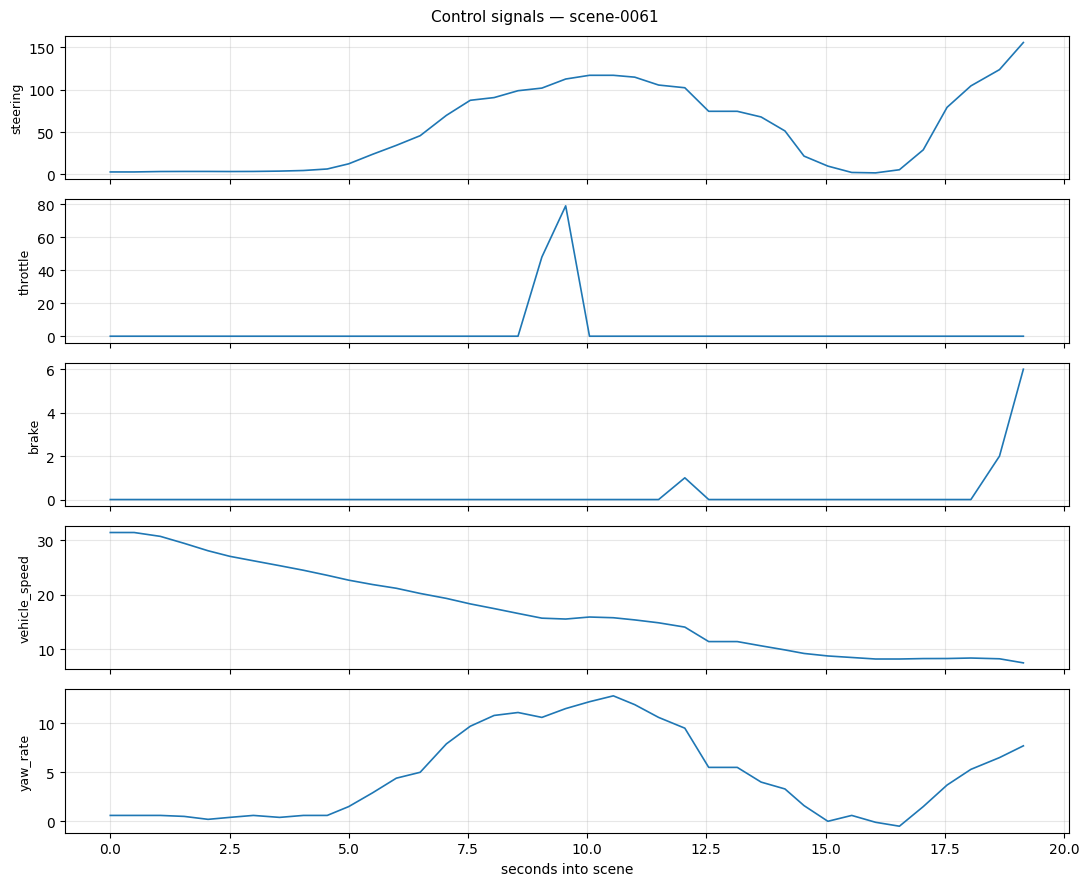

In [ ]:
#@title 8 · Sanity-plot the control signals over one scene

cols = ACTION + STATE
if cols:
    t = (joined["utime"] - joined["utime"].iloc[0]) / 1e6
    fig, axes = plt.subplots(len(cols), 1, figsize=(11, 1.8 * len(cols)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        ax.plot(t, joined[c], lw=1.2)
        ax.set_ylabel(c, fontsize=9)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("seconds into scene")
    plt.suptitle(f"Control signals — {scene['name']}", fontsize=11)
    plt.tight_layout(); plt.show()
else:
    print("No expected columns found — check the printout in cell 7 and adjust.")